# Rôle 3 : analyse exploratoire des textes

Objectif : connaître les 2 000 documents avant de construire `extract` et `retrieve`.

1. Lecture et nettoyage des documents
2. Longueurs des textes
3. Vocabulaire et mots les plus fréquents
4. Mots caractéristiques de chaque secteur
5. Découpage en passages pour la recherche
6. Conséquences pour la suite

Cette analyse est **descriptive** : elle ne règle aucun paramètre appris. Le vocabulaire des modèles de `extract` sera appris sur le seul jeu d'entraînement, après la séparation entraînement / validation / test.

In [1]:
import logging
import re
import sys
from collections import Counter
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from sklearn.feature_extraction.text import ENGLISH_STOP_WORDS, CountVectorizer, TfidfVectorizer

RACINE = Path.cwd().resolve().parents[1]
sys.path.insert(0, str(RACINE))
from src import nlp

FIGURES = RACINE / "reports" / "role3" / "figures"
FIGURES.mkdir(parents=True, exist_ok=True)
logging.basicConfig(level=logging.WARNING)
pd.set_option("display.width", 140)
plt.rcParams.update({"figure.dpi": 110, "axes.spines.top": False, "axes.spines.right": False})

## 1. Lecture et nettoyage

Chaque fichier `data/docs/<id_projet>.txt` contient un en-tête (nom, pays, secteur, coût, durée, année, statut), puis l'objectif de développement (PDO) et le résumé, en anglais, recopiés de la Banque mondiale.

On n'analyse que **le PDO et le résumé** (fonction `nlp.corps`) : l'en-tête répète des chiffres que les autres rôles utilisent déjà.

In [2]:
documents = nlp.charger_documents()
projets = pd.read_csv(RACINE / "data" / "processed" / "projets.csv").set_index("id_projet")
print(len(documents), "documents ;", len(projets), "projets dans projets.csv ;",
      "identifiants identiques :", set(documents) == set(projets.index))
print()
print(documents["P171266"])

2000 documents ; 2000 projets dans projets.csv ; identifiants identiques : True

Projet : Agriculture Resilience and Competitiveness Project
Identifiant : P171266
Pays : Bosnia and Herzegovina (Europe et Asie centrale)
Secteur : Agriculture
Coût total : 68.5 millions de dollars
Durée prévue : 69 mois
Année d'approbation : 2022
Statut : en_cours

Objectif de développement (PDO) :
The Project Development Objective is to increase climate resilience and competitiveness of the agriculture sector.

Résumé :
The development objective of Agriculture Resilience and Competitiveness Project for Bosnia and Herzegovina is to increase climate resilience and competitiveness of the agriculture sector. This project has two components. 1) The first component, Enhancing Public Support Resilience and Traceability, has the following sub-components: (i) Enhancing Agriculture Information Systems; and (ii) Supporting Climate-Resilient Agriculture. 2) The second component, Improving Agriculture Productivity, A

Les textes anciens ont des défauts : PDO entièrement en majuscules, mots coupés par un tiret de fin de ligne (« UTILIZA- TION »), espaces en trop. `nlp.nettoyer` les répare. Exemple avant / après :

In [3]:
brut = documents["P000001"].split(nlp.MARQUEUR_PDO)[1].split(nlp.MARQUEUR_RESUME)[0].strip()
print("Avant :", brut)
print("Après :", nlp.nettoyer(brut))

Avant : CONSERVATION OF BIO-DIVERSITY. OBJECTIVE IS TO ESTABLISH A PILOT, SUSTAINABLE AND LOCALLY APPROPRIATE COMMUNITY BASED WILDLIFE UTILIZA- TION OPERATION IN WEST AFRICA.
Après : Conservation of bio-diversity. Objective is to establish a pilot, sustainable and locally appropriate community based wildlife utilization operation in west africa.


In [4]:
def section(document: str, marqueur: str, suivant: str | None) -> str:
    """Texte brut d'une section du document."""
    texte = document.split(marqueur, 1)[1]
    return texte.split(suivant, 1)[0].strip() if suivant else texte.strip()

df = pd.DataFrame({
    "pdo": {i: section(d, nlp.MARQUEUR_PDO, nlp.MARQUEUR_RESUME) for i, d in documents.items()},
    "resume": {i: section(d, nlp.MARQUEUR_RESUME, None) for i, d in documents.items()},
    "corps": {i: nlp.corps(d) for i, d in documents.items()},
}).join(projets[["secteur", "statut", "annee_approbation"]])
df["resume_absent"] = df["resume"].eq(nlp.ABSENT)
df["majuscules"] = df["pdo"].map(lambda t: sum(c.isupper() for c in t) / max(sum(c.isalpha() for c in t), 1) > 0.8)
for c in ("pdo", "resume", "corps"):
    df[f"mots_{c}"] = df[c].where(df[c] != nlp.ABSENT, "").str.split().str.len()
print(f"Résumé absent : {df.resume_absent.sum()} documents ({df.resume_absent.mean():.0%})")
print(f"PDO en majuscules : {df.majuscules.sum()} documents ({df.majuscules.mean():.0%})")

Résumé absent : 526 documents (26%)
PDO en majuscules : 285 documents (14%)


## 2. Longueurs des textes

In [5]:
df[["mots_pdo", "mots_resume", "mots_corps"]].describe(percentiles=[.1, .25, .5, .75, .9]).round(0)

,mots_pdo,mots_resume,mots_corps
count,2000.0,2000.0,2000.0
mean,44.0,180.0,224.0
std,50.0,179.0,182.0
min,9.0,0.0,11.0
10%,17.0,0.0,28.0
25%,22.0,0.0,92.0
50%,30.0,171.0,211.0
75%,45.0,240.0,294.0
90%,86.0,342.0,400.0
max,1167.0,1219.0,1259.0


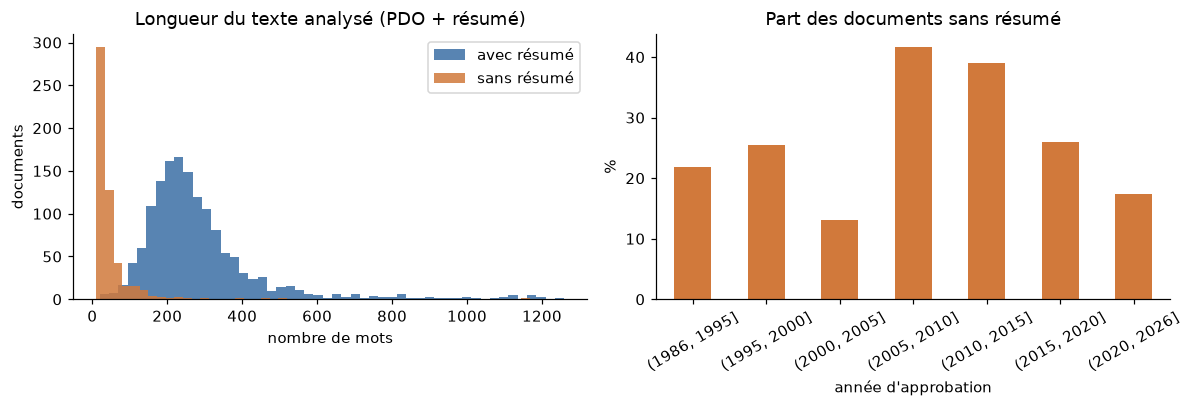

In [6]:
fig, axes = plt.subplots(1, 2, figsize=(11, 3.8))
axes[0].hist(df.loc[~df.resume_absent, "mots_corps"], bins=50, color="#3b6ea5", alpha=.85, label="avec résumé")
axes[0].hist(df.loc[df.resume_absent, "mots_corps"], bins=50, color="#d1793b", alpha=.85, label="sans résumé")
axes[0].set(title="Longueur du texte analysé (PDO + résumé)", xlabel="nombre de mots", ylabel="documents")
axes[0].legend()
par_annee = df.groupby(pd.cut(df.annee_approbation, [1986, 1995, 2000, 2005, 2010, 2015, 2020, 2026]))
par_annee["resume_absent"].mean().mul(100).plot.bar(ax=axes[1], color="#d1793b")
axes[1].set(title="Part des documents sans résumé", xlabel="année d'approbation", ylabel="%")
axes[1].tick_params(axis="x", rotation=30)
fig.tight_layout()
fig.savefig(FIGURES / "longueurs_textes.png", bbox_inches="tight")

In [7]:
(df.groupby("secteur")
   .agg(documents=("corps", "size"), mots_medians=("mots_corps", "median"),
        sans_resume=("resume_absent", "mean"))
   .assign(sans_resume=lambda t: (t.sans_resume * 100).round(0))
   .sort_values("documents", ascending=False))

,documents,mots_medians,sans_resume
secteur,,,
Gouvernance,392,209.0,27.0
Agriculture,263,200.0,33.0
Transport,217,208.0,22.0
Énergie,200,209.5,26.0
Éducation,196,212.0,20.0
Eau et assainissement,186,227.5,27.0
Protection sociale,165,191.0,35.0
Santé,153,229.0,21.0
Industrie et commerce,92,194.5,28.0


**À retenir.**

- Les textes sont courts : quelques centaines de mots au plus, et souvent bien moins.
- Un quart des documents (526) n'ont pas de résumé : il ne reste que le PDO, en général une ou deux phrases. Ce sont surtout des projets anciens. Pour eux, `extract` aura peu d'indices et doit rester prudent (note neutre 3 si le texte est trop court).
- Les longueurs varient peu d'un secteur à l'autre : la longueur ne trahit pas le secteur.

## 3. Vocabulaire

Mise en minuscules, découpage en mots de 2 lettres ou plus, sans les mots vides anglais (*the, of, and*…) de scikit-learn.

In [8]:
jetons = [m for t in df.corps for m in re.findall(r"[a-z][a-z\-]+", t.lower())]
pleins = [m for m in jetons if m not in ENGLISH_STOP_WORDS]
frequences = Counter(pleins)
print(f"{len(jetons):,} mots au total, {len(set(jetons)):,} mots différents")
print(f"sans mots vides : {len(pleins):,} mots, {len(frequences):,} différents")
print(f"mots vus une seule fois (hapax) : {sum(1 for c in frequences.values() if c == 1):,}")

434,318 mots au total, 15,675 mots différents
sans mots vides : 274,150 mots, 15,421 différents
mots vus une seule fois (hapax) : 6,957


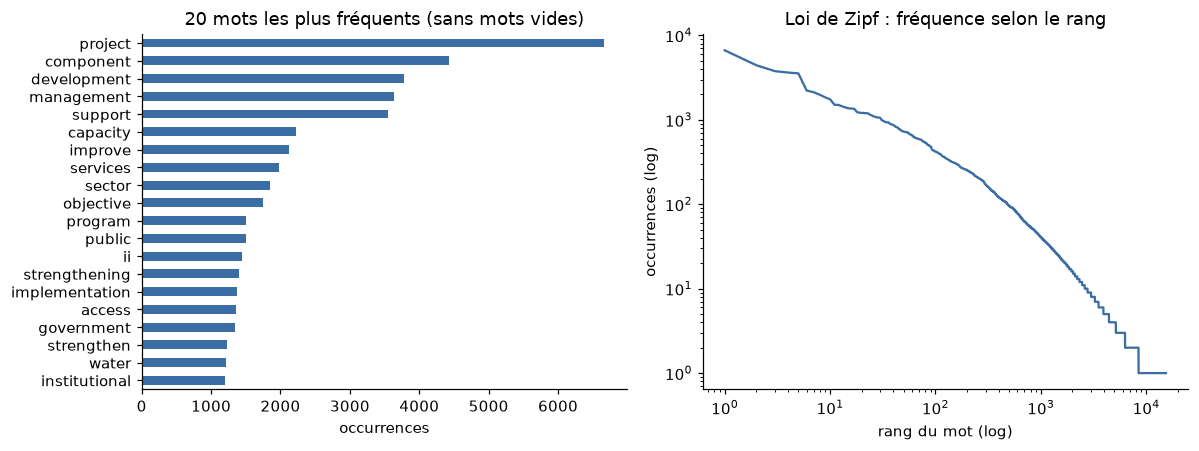

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4.2))
haut = pd.Series(dict(frequences.most_common(20))).sort_values()
haut.plot.barh(ax=axes[0], color="#3b6ea5")
axes[0].set(title="20 mots les plus fréquents (sans mots vides)", xlabel="occurrences")
rangs = np.arange(1, len(frequences) + 1)
axes[1].loglog(rangs, sorted(frequences.values(), reverse=True), color="#3b6ea5")
axes[1].set(title="Loi de Zipf : fréquence selon le rang", xlabel="rang du mot (log)", ylabel="occurrences (log)")
fig.tight_layout()
fig.savefig(FIGURES / "vocabulaire.png", bbox_inches="tight")

Les mots les plus fréquents sont ceux du **jargon de la Banque mondiale** (*project, component, development, management, support*), plus *ii*, reste des énumérations « (i), (ii) » : ils sont présents presque partout et ne distinguent pas les projets. C'est exactement ce que la pondération **TF-IDF** corrige : un mot présent dans tous les documents reçoit un poids proche de zéro.

La courbe en log-log est presque une droite : le vocabulaire suit la loi de Zipf, avec beaucoup de mots rares. D'où l'intérêt de filtrer les mots trop rares (`min_df`) dans les modèles appris.

In [10]:
bigrammes = CountVectorizer(ngram_range=(2, 2), stop_words="english", min_df=5)
comptes = bigrammes.fit_transform(df.corps)
pd.Series(np.asarray(comptes.sum(axis=0)).ravel(), index=bigrammes.get_feature_names_out()).nlargest(15)

development objective    998
project management       743
technical assistance     660
project development      567
capacity building        534
second component         512
component project        470
private sector           463
sub components           428
monitoring evaluation    415
components component     400
covid 19                 377
component support        374
project components       345
service delivery         334
dtype: int64

Les paires les plus fréquentes sont, elles aussi, surtout du jargon (*development objective, project management, second component*). Quelques-unes portent un vrai sens que les mots seuls perdent : *private sector, capacity building, service delivery, covid 19*. Les modèles TF-IDF utiliseront donc les mots seuls **et** les paires de mots (`ngram_range=(1, 2)`), en laissant la pondération écraser le jargon.

## 4. Mots caractéristiques de chaque secteur

Pour chaque secteur, on moyenne les poids TF-IDF de ses documents et on garde les 8 mots les plus lourds. C'est un contrôle de cohérence : si les textes sont informatifs, chaque secteur doit avoir son vocabulaire propre.

In [11]:
tfidf = TfidfVectorizer(stop_words="english", min_df=5, max_df=0.5, sublinear_tf=True)
X = tfidf.fit_transform(df.corps)
mots = tfidf.get_feature_names_out()
caracteristiques = {}
for secteur, lignes in df.reset_index().groupby("secteur").groups.items():
    moyenne = np.asarray(X[list(lignes)].mean(axis=0)).ravel()
    caracteristiques[secteur] = ", ".join(mots[np.argsort(-moyenne)[:8]])
pd.set_option("display.max_colwidth", 120)
pd.Series(caracteristiques, name="mots caractéristiques").to_frame()

,mots caractéristiques
Agriculture,"agricultural, component, agriculture, sustainable, production, farmers, irrigation, productivity"
Eau et assainissement,"water, sanitation, supply, urban, services, component, wastewater, sustainable"
Finance,"financial, sector, finance, credit, banking, business, medium, private"
Gouvernance,"public, government, fiscal, sector, strengthen, policy, program, component"
Industrie et commerce,"sector, component, private, competitiveness, investment, value, enterprises, export"
Numérique,"digital, broadband, services, access, infrastructure, component, government, data"
Protection sociale,"social, poor, vulnerable, households, net, access, cash, safety"
Santé,"health, care, services, quality, utilization, covid, nutrition, 19"
Transport,"road, transport, roads, infrastructure, safety, maintenance, component, network"
Éducation,"education, learning, quality, school, schools, secondary, primary, teaching"


Chaque secteur a bien un vocabulaire distinct (*energy, electricity, power* pour l'énergie, *education, learning, school* pour l'éducation, *road, transport* pour le transport, *poor, vulnerable, households* pour la protection sociale). Le mot *component* revient encore dans plusieurs secteurs : c'est du jargon que le filtre `max_df=0.5` n'a pas suffi à retirer. Les textes sont donc informatifs, ce qui justifie de chercher les notes qualitatives et les passages pertinents dans le texte.

Visualisation en deux dimensions (réduction de dimension par SVD tronquée, appelée aussi analyse sémantique latente) :

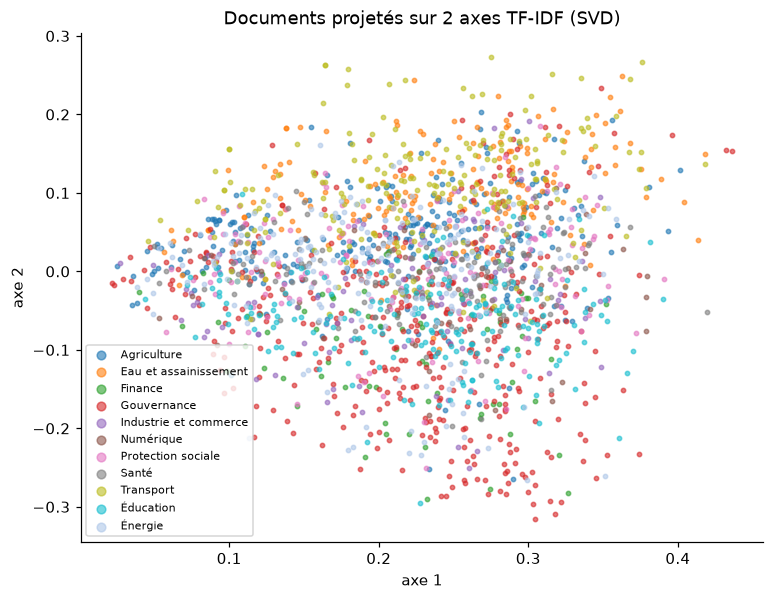

In [12]:
from sklearn.decomposition import TruncatedSVD

coords = TruncatedSVD(n_components=2, random_state=42).fit_transform(X)
fig, ax = plt.subplots(figsize=(8, 6))
palette = plt.get_cmap("tab20").colors
for (secteur, lignes), couleur in zip(df.reset_index().groupby("secteur").groups.items(), palette[::2] + palette[1::2]):
    ax.scatter(coords[lignes, 0], coords[lignes, 1], s=8, alpha=.6, color=couleur, label=secteur)
ax.set(title="Documents projetés sur 2 axes TF-IDF (SVD)", xlabel="axe 1", ylabel="axe 2")
ax.legend(fontsize=7, markerscale=2, loc="best")
fig.savefig(FIGURES / "projection_svd_secteurs.png", bbox_inches="tight")

Sur deux axes seulement, les secteurs se mélangent presque entièrement. On devine une tendance : le transport et l'eau plutôt en haut, la gouvernance plutôt en bas. Deux axes ne gardent qu'une petite part de l'information, et beaucoup de projets touchent plusieurs secteurs : cette figure montre surtout que **la séparation se fait dans un espace de grande dimension**, pas dans un plan.

## 5. Découpage en passages pour la recherche

`retrieve` doit rendre des **passages** et pas des documents entiers : un passage court se cite facilement dans la recommandation de l'agent, et le modèle d'embeddings ne lit que les 256 premiers jetons d'un texte (environ 180 mots).

Règle choisie (`nlp.decouper_passages`) : fenêtres de 3 phrases qui avancent de 2 (une phrase commune entre deux passages voisins, pour ne pas couper une idée en deux). Une « phrase » de plus de 60 mots (énumération sans point) est coupée, donc un passage fait au plus 180 mots.

In [13]:
passages = nlp.decouper_passages(documents)
lp = pd.Series([len(p["passage"].split()) for p in passages])
par_doc = pd.Series(Counter(p["id_projet"] for p in passages))
print(f"{len(passages):,} passages ; {par_doc.size} documents couverts sur {len(documents)}")
print("passages par document :", par_doc.describe()[["min", "50%", "mean", "max"]].round(1).to_dict())
lp.describe(percentiles=[.1, .5, .9]).round(0)

8,293 passages ; 2000 documents couverts sur 2000
passages par document : {'min': 1.0, '50%': 4.0, 'mean': 4.1, 'max': 28.0}


count    8293.0
mean       75.0
std        29.0
min         3.0
10%        38.0
50%        74.0
90%       115.0
max       180.0
dtype: float64

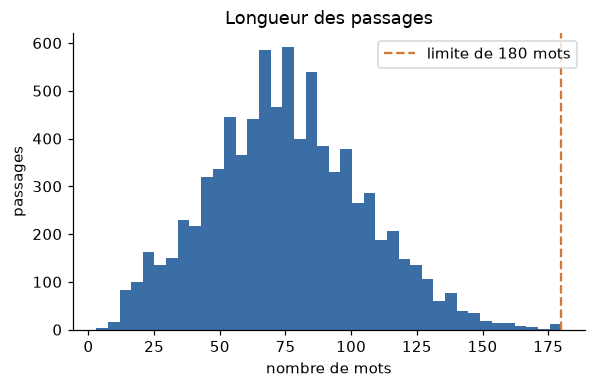

In [14]:
fig, ax = plt.subplots(figsize=(6, 3.5))
ax.hist(lp, bins=40, color="#3b6ea5")
ax.axvline(180, color="#d1793b", linestyle="--", label="limite de 180 mots")
ax.set(title="Longueur des passages", xlabel="nombre de mots", ylabel="passages")
ax.legend()
fig.savefig(FIGURES / "longueurs_passages.png", bbox_inches="tight")

## 6. Conséquences pour la suite

| Constat | Décision |
|---|---|
| L'en-tête répète des chiffres déjà utilisés par les autres rôles | On n'analyse que le PDO et le résumé |
| PDO anciens en majuscules, mots coupés | Nettoyage avant tout traitement (`nlp.nettoyer`) |
| 26 % des documents réduits à une ou deux phrases | `extract` donne la note neutre 3 quand le texte est trop court |
| Mots du jargon présents partout | Pondération TF-IDF, mots vides retirés |
| Vocabulaire à longue traîne (loi de Zipf) | Filtrer les mots trop rares (`min_df`) dans les modèles appris |
| Paires de mots porteuses de sens | Mots seuls et paires de mots (`ngram_range=(1, 2)`) |
| Vocabulaire propre à chaque secteur | Les textes sont informatifs : la recherche et l'extraction ont du signal |
| Embeddings limités à environ 180 mots | Passages de 3 phrases, 180 mots au plus |